In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import umap.plot

from sklearn.preprocessing import StandardScaler
import clustering_functions as cf

import warnings
from numba.core.errors import NumbaWarning

warnings.simplefilter('ignore', category=NumbaWarning)


/Users/theresewild/miniforge3/envs/chemspace/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/theresewild/miniforge3/envs/chemspace/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/theresewild/miniforge3/envs/chemspace/lib/python3.11/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more t

# Read in Data

In [5]:
feature_input_file = 'sample_input' #a file with smiles, descriptors and IDs 
feature_sheet_name = 'Sheet1'
feature_start_column = 5 #column where descriptors start, 0-indexed
feature_header_rows = 1 # adjust as needed 

feature_id_column_name= 'Compound_Name' 
feature_smiles_column_name= 'smiles' 
feature_type_column_name = 'type' #if you don't need to plot any subsets enter: None (not 'None')

#if you want to visualize data by a response variable
response_input_file = None # or leave as None 
response_column_name = None 
response_header_rows = None 
response_id_column_name = None 

#_______________________________________________________________________________
#_______________________________________________________________________________
feature_input_df = pd.read_excel(feature_input_file+'.xlsx', sheet_name=feature_sheet_name, header=feature_header_rows)
feature_input_df_shape = feature_input_df.shape
allowed_empty = [feature_smiles_column_name] 
feature_input_df.dropna(subset=[col for col in feature_input_df.columns if col not in allowed_empty], inplace=True) #drop columns with empty values, allow empty smiles
feature_input_df.reset_index(drop=True, inplace=True)
feature_input_df_nona = feature_input_df.shape
if feature_input_df_shape[0] != feature_input_df_nona[0]:
    print('Some rows with missing values were removed')
    print('Original number of datapoints: ', feature_input_df_shape[0])
    print('New number of datapoints: ', feature_input_df_nona[0])

feature_df = feature_input_df.iloc[:,feature_start_column:] #just descriptors 
data = feature_input_df.copy()
# data = cf.get_mol_svg(feature_input_df, feature_smiles_column_name, feature_id_column_name) #sets up for interactive plots

ID = data[feature_id_column_name]
smiles = data[feature_smiles_column_name]

if feature_type_column_name is not None:
   type_column = data[feature_type_column_name]
   type_column.reset_index(drop=True, inplace=True)
if feature_type_column_name is None:
   type_column = None

if response_input_file is not None:
   response_column = data[response_column_name]
   response_input = pd.read_excel(response_input_file+'.xlsx', sheet_name=feature_sheet_name, header=response_header_rows)
   response_df = response_input.filter(items=[response_id_column_name, response_column_name])
   data = pd.merge(response_df, data, on=response_id_column_name)
else:
   response_column = None

In [6]:
# collinearity filter - add to cell above + have threshold as editing section 
threshold = 0.7
print(f'Shape of descriptors file before removing parameters with R^2 > {threshold} :',feature_df.shape)
df_corr = feature_df.corr()
df_not_correlated = ~(df_corr.mask(np.tril(np.ones([len(df_corr)]*2, dtype=bool))).abs() > threshold).any()
un_corr_idx = df_not_correlated.loc[df_not_correlated[df_not_correlated.index] == True].index
feature_df = feature_df[un_corr_idx]
print(f'Shape of descriptors file after removing parameters with R^2 > {threshold} : ',feature_df.shape)

Shape of descriptors file before removing parameters with R^2 > 0.7 : (450, 290)
Shape of descriptors file after removing parameters with R^2 > 0.7 :  (450, 40)


In [7]:
#scale data
scaler = StandardScaler()
features_scaled = scaler.fit_transform(feature_df)

# Perform Dimensionality Reduction if Needed

### UMAP

#### Run and Plot UMAP

/Users/theresewild/miniforge3/envs/chemspace/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


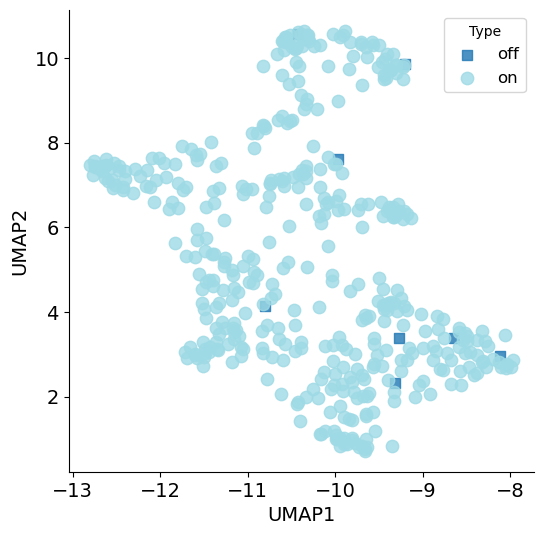

In [8]:
feature_set = features_scaled
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'umap_coordinates.xlsx'
plot_file_name = 'umap_plot.png'

#tune hyperparameters 
# for more info on UMAP + UMAP hyperparameters: pair-code.github.io/understanding-umap/

n_neighbors = 15 #umap default is 15, reasonable range 3-100
minimum_distance = 0.1 #umap default is 0.1, reasonable range 0.0-0.5
distance_metric = 'manhattan' 
random_state = 42 #for reproducibility (on a single machine)

#choose plot parameters - no subsets
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'o' #point shape
size = 100 #point size
font_size = 14

#choose plot parameters - subsets (leave as None if not plotting subsets or if you want to use default plot settings)
alpha_value_mapping = None #dictionary {'type_1': 0.7, 'type_2': 0.5, ...}
color_mapping = None #dictionary {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
marker_mapping = None #dictionary {'type_1': 'o', 'type_2': 's', ...}
size_mapping = None #dictionary {'type_1': 100, 'type_2': 200, ...}
plot_order = None # if you want to specify the order of plotting subsets for visualization purposes

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
palette = 'plasma' #choose a color palette from matplotlib

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

umap_df = cf.plot_umap(features=feature_set, ID=ID, image=None, smiles=smiles, type_column=type_column, response_column=response_column, n_neighbors=n_neighbors,
                      min_dist=minimum_distance, distance_metric=distance_metric, random_state=random_state, alpha=alpha, color=color,
                      marker=marker, size=size, export_excel=export_to_excel, save_plot=save_plot_as_png, font_size=font_size,
                      alpha_value_mapping=alpha_value_mapping, color_mapping=color_mapping, marker_mapping=marker_mapping,
                      size_mapping=size_mapping, plot_order=plot_order,  excel_filename=excel_file_name, plot_filename=plot_file_name, heatmap=heatmap, palette=palette)


### TSNE

#### Run and Plot TSNE

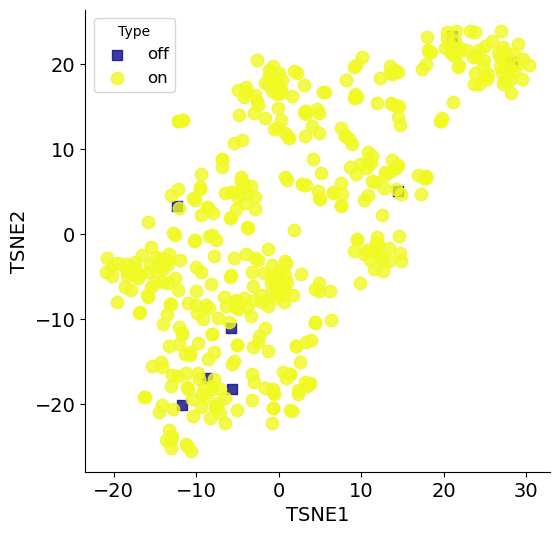

In [10]:
feature_set = features_scaled
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'tsne_coordinates.xlsx'
plot_file_name = 'tsne_plot.png'

#tune hyperparameters 
# for more info on TSNE + TSNE hyperparameters https://distill.pub/2016/misread-tsne/
perplexity = 30 #tsne default is 30
early_exaggeration = 12 #tsne default is 12
learning_rate = 'auto' #range 10-1000
max_iterations = 1000 #tsne default is 1000
distance_metric = 'manhattan' 
random_state = 42 #for reproducibility 

#choose plot parameters - no subsets
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'o' #point shape
size = 100 #point size
font_size = 14

#choose plot parameters - subsets (leave as None if not plotting subsets or if you want to use default plot settings)
alpha_value_mapping = None #dictionary {'type_1': 0.7, 'type_2': 0.5, ...}
color_mapping = None #dictionary {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
marker_mapping = None #dictionary {'type_1': 'o', 'type_2': 's', ...}
size_mapping = None #dictionary {'type_1': 100, 'type_2': 200, ...}
plot_order = None # if you want to specify the order of plotting subsets for visualization purposes

#if you want plot TSNE by a response variable - will override type_column if set to True 
heatmap = False
palette = 'plasma' #choose a color palette from matplotlib

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

tsne_df = cf.plot_tsne(features=feature_set, ID=ID, image=None, smiles=smiles, type_column=type_column, response_column=response_column, perplexity=perplexity, init='random',
                       early_exaggeration=early_exaggeration,learning_rate=learning_rate, distance_metric=distance_metric, random_state=random_state,
                       alpha=alpha, color=color,marker=marker, size=size, export_excel=export_to_excel, save_plot=save_plot_as_png, font_size=font_size,
                      alpha_value_mapping=alpha_value_mapping, color_mapping=color_mapping, marker_mapping=marker_mapping,
                      size_mapping=size_mapping, plot_order=plot_order,  excel_filename=excel_file_name, plot_filename=plot_file_name, heatmap=heatmap, palette=palette)


### PCA

#### Run and Plot PCA

Total variance explained by PCs: 72.6 %

Percentage of explained variance per principal component:
PC1   21.4%
PC2   10.8%
PC3   10.1%
PC4   6.9%
PC5   5.9%
PC6   4.6%
PC7   4.4%
PC8   3.3%
PC9   3.0%
PC10   2.3%
Feature contributions saved to pca_feature_loadings.xlsx


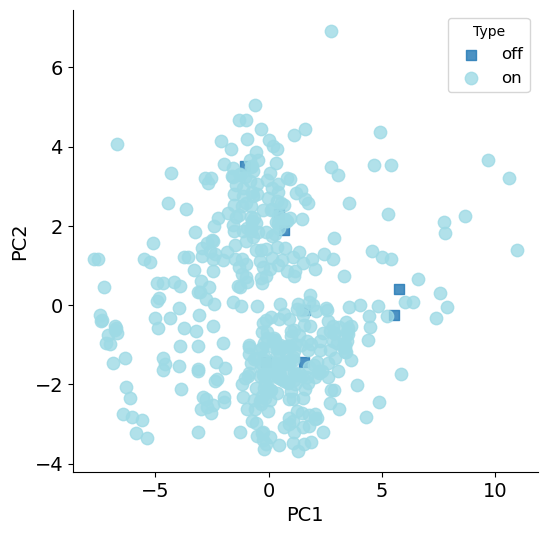

In [11]:
feature_set = features_scaled
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
export_feature_loadings_to_excel = True #if you want to save feature loadings as an excel file, set to True
excel_file_name = 'pca_coordinates.xlsx'
feature_loading_file_name = 'pca_feature_loadings.xlsx'
plot_file_name = 'pca_plot.png'

n_components = 10 #number of components to keep
PCx = 'PC1' #which principal component to plot on x-axis
PCy = 'PC2' #which principal component to plot on y-axis
PCz = None #if you want a 3D plot, specify which principal component to plot on z-axis

#choose plot parameters - no subsets
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'o' #point shape
size = 100 #point size
font_size = 14

#choose plot parameters - subsets (leave as None if not plotting subsets or if you want to use default plot settings)
alpha_value_mapping = None #dictionary {'type_1': 0.7, 'type_2': 0.5, ...}
color_mapping = None #dictionary {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
marker_mapping = None #dictionary {'type_1': 'o', 'type_2': 's', ...}
size_mapping = None #dictionary {'type_1': 100, 'type_2': 200, ...}
plot_order = None # if you want to specify the order of plotting subsets for visualization purposes

#if you want plot TSNE by a response variable - will override type_column if set to True 
heatmap = False
palette = 'plasma' #choose a color palette from matplotlib

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

pca_df =  cf.plot_pca(feature_df=feature_df, features=feature_set, ID=ID, image=None, smiles=smiles, type_column=type_column, response_column=response_column, n_components=n_components,
            alpha=alpha, color=color,marker=marker, size=size, export_excel=export_to_excel, export_feature_excel=export_feature_loadings_to_excel, save_plot=save_plot_as_png, font_size=font_size,
                      alpha_value_mapping=alpha_value_mapping, color_mapping=color_mapping, marker_mapping=marker_mapping,
                      size_mapping=size_mapping, plot_order=plot_order, pc_x = PCx, pc_y = PCy, pc_z = PCz, 
                      excel_filename=excel_file_name, plot_filename=plot_file_name, feature_filename = feature_loading_file_name, heatmap=heatmap, palette=palette)

### Plot Descriptor vs. Descriptor

#### Simple Decriptor v. Descriptor (v. Descriptor) Plotting

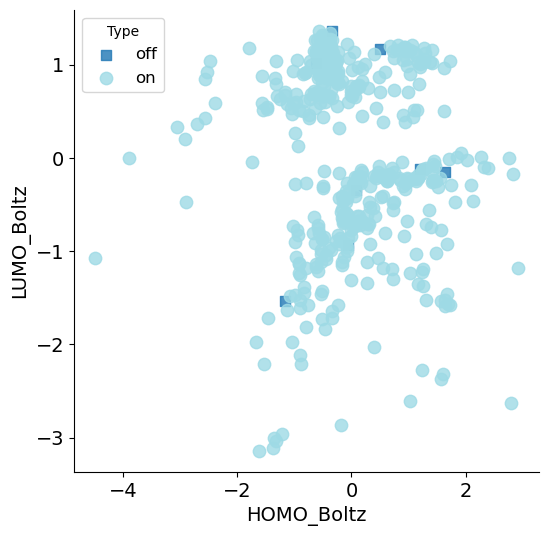

In [12]:
feature_set = pd.DataFrame(features_scaled, columns=feature_df.columns)
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'feature1_vs_feature2_coordinates.xlsx'
plot_file_name = 'feature1_vs_feature2_plot.png'

feature_x= 'HOMO_Boltz' 
feature_y = 'LUMO_Boltz'  
feature_z = None  # if you want to plot in 3D, set to 'feature#'

#choose plot parameters - no subsets
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'o' #point shape
size = 100 #point size
font_size = 14

#choose plot parameters - subsets (leave as None if not plotting subsets or if you want to use default plot settings)
alpha_value_mapping = None #dictionary {'type_1': 0.7, 'type_2': 0.5, ...}
color_mapping = None #dictionary {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
marker_mapping = None #dictionary {'type_1': 'o', 'type_2': 's', ...}
size_mapping = None #dictionary {'type_1': 100, 'type_2': 200, ...}
plot_order = None # if you want to specify the order of plotting subsets for visualization purposes

#if you want plot TSNE by a response variable - will override type_column if set to True 
heatmap = False
palette = 'plasma' #choose a color palette from matplotlib

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

chem_space_df =  cf.plot_feature_v_feature(features=feature_set, ID=ID, image=None, smiles=smiles, type_column=type_column, response_column=response_column,
            alpha=alpha, color=color,marker=marker, size=size, export_excel=export_to_excel, save_plot=save_plot_as_png, font_size=font_size,
                      alpha_value_mapping=alpha_value_mapping, color_mapping=color_mapping, marker_mapping=marker_mapping,
                      size_mapping=size_mapping, plot_order=plot_order, feature_x = feature_x, feature_y = feature_y, feature_z = feature_z,
                      excel_filename=excel_file_name, plot_filename=plot_file_name, heatmap=heatmap, palette=palette)

### Plot Interactive Chemical Space

In [13]:
df = pd.read_excel('pca_coordinates.xlsx')
x_coordinates = 'PC1'
y_coordinates = 'PC2'
id_column = 'id'
smiles_column = 'smiles'

#stylize markers
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'circle' #point shape
size = 10 #point size
linewidth = 1
linecolor = 'black'

#if you want to stylize markers by a reponse variable
size_column = None #column name for size scaling
alpha_column = None #column name for alpha scaling
marker_column = None #column name for marker shapes

#stylize figure 
title = 'Chemical Space Map by PCA'
x_label = 'Principal Component 1'
y_label = 'Principal Component 2'
fig_width = 600
fig_height = 600

###### -------- if you want to plot subgroups -------- ######
subgroup = False #change to True if you want to plot subgroups
subgroup_col = 'type' #column name for subgroups
subgroup_palette = None #change to continous color pallette if desired
categorical = False #or set to True if you want discrete colors for subgroups
category_dict = None #enter dict of custom colors: {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
categorical_palette = None #or choose a plotly categorical palette if desired

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

int_plot = cf.int_scatter_dash(df, x_col = x_coordinates, y_col = y_coordinates, 
            smiles_col=smiles_column, id_col=id_column, molSize=(150,150), 
            marker_size=size, marker_symbol=marker, marker_color=color,
            marker_alpha = 0.7, linewidth=linewidth, lincolor=linecolor, 
            plot_title=title, x_label=x_label, y_label=y_label, fig_width=fig_width, fig_height=fig_height,
            subgroup=subgroup, subgroup_col=subgroup_col, subgroup_palette=subgroup_palette,
            categorical=categorical, category_dict=category_dict, categorical_palette=categorical_palette,
            size_col=None, min_size=1, max_size=20,
            alpha_col=None, min_alpha=0.5, max_alpha=1.0,
            marker_col=None,debug=False)

#### Simple Descriptor v. Descriptor Plot

In [ ]:
feature_x = 'feature1'
feature_y = 'feature2'

int_plt = cf.scatter_plot(chem_space_df, x=feature_x, y=feature_y, svgs='image', hover_list=['name'], size=10, 
                       alpha=0.8 )
int_plt

# Clustering Techniques

### Choose Number of Clusters

In [ ]:
# see silhouette scores for different numbers of clusters
# ideal plot: clusters have above average silhouette scores, size of the silhouette plots are similar 
# and thickness of the plot for each cluster is uniform
# higher score (up to 1) indicates better clustering

scoring_method = 'silhouette_scores' #options: silhouette_scores, aic_bic_scores, elbow_method

df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'

random_state = 42
min_clusters = 2
max_clusters = 10
clustering_algorithm = cf.kmeans_clustering

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
if scoring_method == 'silhouette_scores':
    silhouette_scoring = cf.silhouette_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)
elif scoring_method == 'aic_bic_scores':
    aic_scoring = cf.aic_bic_inertia_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)  
elif scoring_method == 'elbow_method':
    elbow_method = cf.elbow_method(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm)
else:
    print('Invalid scoring method')


### Choose Clustering Algorithm 

In [ ]:
df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'
random_state = 42

#### HDBSCAN

In [ ]:
#for more info on hyperparameters: hdbscan.readthedocs.io/en/latest/parameter_selection.html
min_cluster_size = 25
min_samples = 15
distance_metric = 'manhattan'

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
hdbscan_clusters, hdbscan_clusters_df = cf.hdbscan_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state,min_cluster_size, min_samples, distance_metric, plot=True)

#### DBSCAN

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
eps = 0.5
min_samples = 5
distance_metric = 'manhattan'

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
dbscan_clusters, dbscan_clusters_df = cf.dbscan_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state,distance_metric, eps, min_samples,  plot=True)

#### K-Means Clustering

In [ ]:
#number of clusters should be selected using one of the algorithms above!
n_clusters = 6

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
kmeans_clusters, kmeans_clusters_df = cf.kmeans_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters,  plot=True)

#### GMM Clustering

In [ ]:
#for more info on covariance types: scikit-learn.org/stable/auto_examples/mixture/plot_gmm_covariances.html#sphx-glr-auto-examples-mixture-plot-gmm-covariances-py
n_clusters = 6
covariance_type = 'full'

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
gmm_clusters, gmm_clusters_df = cf.gmm_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, covariance_type,  plot=True)

#### Agglomerative Clustering (Ward Clustering)

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
n_clusters = 6
distance_metric = 'euclidean'
linkage_type = 'ward'

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
agglomerative_clusters, agg_clusters_df = cf.agglomerative_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, distance_metric, linkage_type,  plot=True)

#### BIRCH Clustering

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html
n_clusters = 6
threshold = 0.5 
branching_factor = 50

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
birch_clusters, birch_clusters_df = cf.BIRCH_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, threshold, branching_factor,  plot=True)

In [ ]:
cluster_df = hdbscan_clusters_df
x_coordinates = 'UMAP1'
y_coordinates = 'UMAP2'

int_plt = scatter_plot(cluster_df, x=x_coordinates, y=y_coordinates, svgs='image', hover_list=['name'], size=10, 
                       alpha=0.8,)
int_plt